# Capstone: Land Use and Land Cover Classification of Sentinel-2 Imagery Under Class Imbalance

**DSA 8401 – Applied Machine Learning**
Patrick Kiprono | Adm. No. 22274 | October 2026

### Learning goals of this project
1. Classify satellite image patches into ten land-use / land-cover classes with CNNs.
2. Show how a **class imbalance** in the training data hurts the rare classes.
3. Test two fixes: **imbalance-aware training** (class weights, focal loss) and **transfer learning** (EfficientNet-B0).
4. Evaluate honestly: a **spatial** train/test split and **macro F1** instead of accuracy.
5. Deploy the best model as a **FastAPI** service.

**Core question:** How well does a CNN recognise *minority* classes when the training data is imbalanced, and does
transfer learning with imbalance-aware training close that gap?

**Dataset:** EuroSAT (Helber et al., 2019): 27,000 Sentinel-2 patches, 64 x 64 pixels, 13 spectral bands, 10 classes.

### How this notebook relates to the pipeline

Training all eight CNNs took about four hours on a CPU-only laptop, so the training is done by the scripts in
`pipeline/` (run with `python run_pipeline.py`), which save every trained model and log every result to MLflow.

This notebook walks through the project **step by step**. It loads the data, looks at it, explains each decision,
trains the random-forest baseline itself, builds the CNN architectures, then **loads each trained CNN and evaluates it
here on the test set**, so every result below is computed in front of you.

| Part | Steps |
|---|---|
| 1. Load and look at the data | 1 – 6 |
| 2. Make the problem realistic: spatial split + imbalance | 7 – 11 |
| 3. Baseline: random forest | 12 – 15 |
| 4. Custom CNN | 16 – 20 |
| 5. Transfer learning: EfficientNet-B0 | 21 – 23 |
| 6. Compare all models: answer the research question | 24 – 29 |
| 7. The champion model | 30 – 32 |
| 8. Deployment: FastAPI | 33 – 34 |
| 9. Summary, limitations, AI-use declaration | |

## 1. Load and look at the data

In [1]:
# Step 1: Import the libraries we need
import json
import os
import sys
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"                 # hide TensorFlow start-up messages
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score

ROOT = Path.cwd().parent                                  # the project folder (this notebook is in notebooks/)
sys.path.insert(0, str(ROOT))
from pipeline.config import CLASSES, BANDS                # the 10 class names and 13 band names
from pipeline.data import to_rgb8, band_features, feature_names

%matplotlib inline

# Make results repeatable
SEED = 42
print("Classes:", CLASSES)

Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Pasture', 'PermanentCrop', 'SeaLake', 'Residential', 'River', 'Industrial', 'Highway']


The ingest step (`pipeline/ingest.py`) has already read all 27,000 GeoTIFF files once and saved:
* `artifacts/metadata.csv`: one row per patch, with its class and its location (latitude / longitude).
* `artifacts/patches.npy`: all pixel values in one array.

In [2]:
# Step 2: Load the table that describes every patch
meta = pd.read_csv(ROOT / "artifacts" / "metadata.csv")
print("Number of patches:", len(meta))
meta.head()

Number of patches:

 27000


,idx,file,class_name,label,lat,lon
0,0,ds/images/remote_sensing/otherDatasets/sentine...,AnnualCrop,0,44.035220,28.559055
1,1,ds/images/remote_sensing/otherDatasets/sentine...,AnnualCrop,0,39.085801,-1.829726
2,2,ds/images/remote_sensing/otherDatasets/sentine...,AnnualCrop,0,48.977295,4.239720
3,3,ds/images/remote_sensing/otherDatasets/sentine...,AnnualCrop,0,48.892610,4.089878
4,4,ds/images/remote_sensing/otherDatasets/sentine...,AnnualCrop,0,51.832851,18.084960


In [3]:
# Step 3: How many patches does each class have?
meta["class_name"].value_counts()

class_name
AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Residential             3000
SeaLake                 3000
Highway                 2500
Industrial              2500
PermanentCrop           2500
River                   2500
Pasture                 2000
Name: count, dtype: int64

**What does this tell us?** The original dataset is nearly balanced (2,000 to 3,000 patches per class). Real
landscapes are not, which is why Part 2 makes the training set imbalanced on purpose.

In [4]:
# Step 4: Load the pixels. mmap_mode="r" reads from disk only what we use, instead of loading all 2.9 GB into memory
patches = np.load(ROOT / "artifacts" / "patches.npy", mmap_mode="r")
print("Shape:", patches.shape, "  ->  (patches, height, width, bands)")
print("Data type:", patches.dtype)

Shape: (27000, 64, 64, 13)   ->  (patches, height, width, bands)
Data type: uint16


Each patch is **64 x 64 pixels x 13 bands**. A pixel is 10 m on the ground, so a patch covers 640 m x 640 m.
The values are reflectance (how much sunlight the surface reflects in each band), stored as whole numbers.

Always look at the images before building a model. To see a patch as a normal photo we take the red, green and blue
bands (B04, B03, B02) and scale them to 0–255 with `to_rgb8`, the same function the model and the API use.

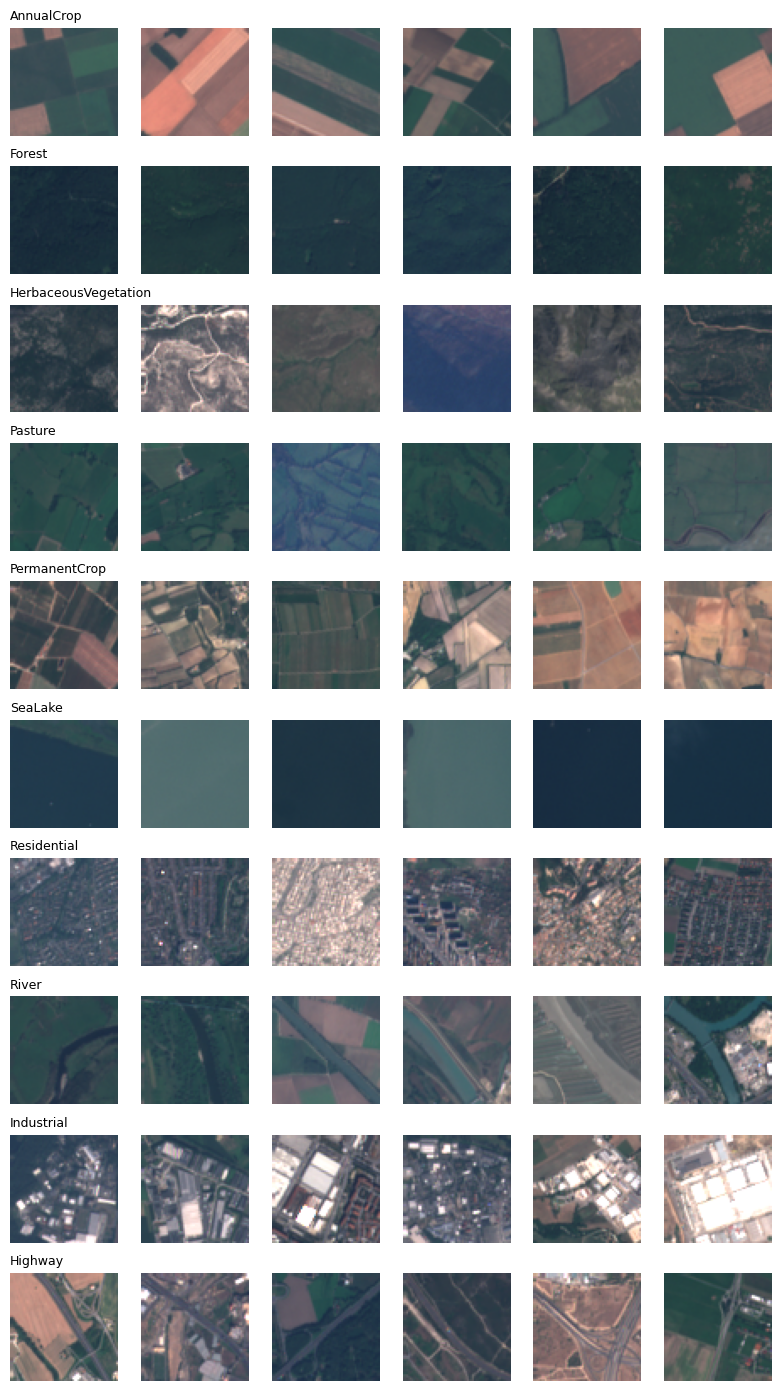

In [5]:
# Step 5: Plot 6 random patches from every class in true colour
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(8, 14))
for row, class_name in enumerate(CLASSES):
    idx = meta[meta["class_name"] == class_name].sample(6, random_state=SEED)["idx"]
    for col, i in enumerate(idx):
        axes[row, col].imshow(to_rgb8(patches[i]))
        axes[row, col].axis("off")
    axes[row, 0].set_title(class_name, loc="left", fontsize=9)
plt.tight_layout()
plt.show()

**What does this tell us?** Some classes are easy to recognise by eye (SeaLake is flat and dark, Industrial has
large bright roofs). Others are hard: a **Highway** patch is mostly fields or forest with a thin road through it, and
AnnualCrop, PermanentCrop and Pasture all look like fields. These are the classes we should expect the model to confuse.

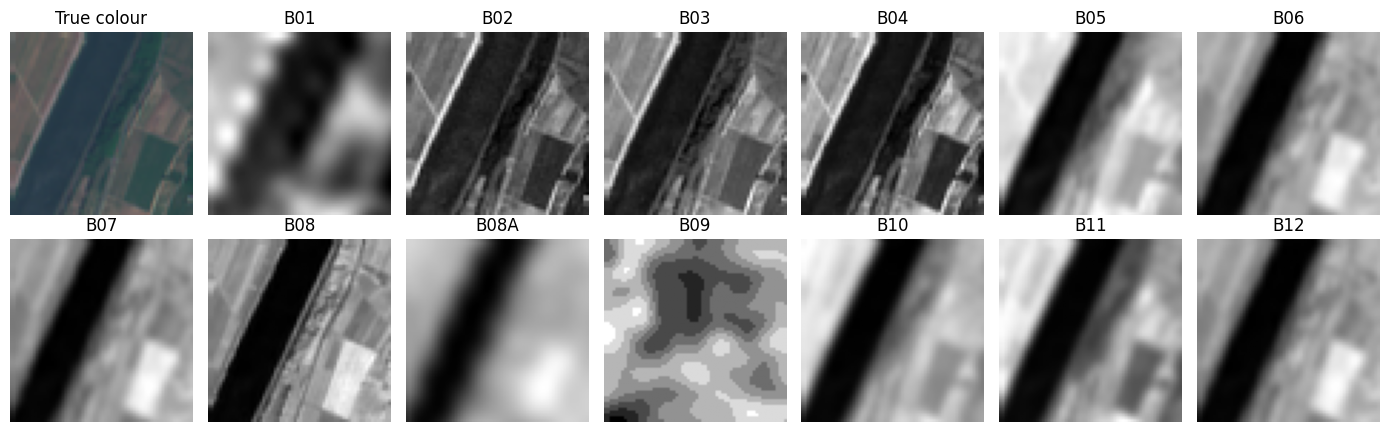

In [6]:
# Step 6: Look at all 13 bands of one patch - a satellite sees much more than the human eye
i = meta[meta["class_name"] == "River"]["idx"].iloc[0]
fig, axes = plt.subplots(2, 7, figsize=(14, 4.4))
axes[0, 0].imshow(to_rgb8(patches[i]))
axes[0, 0].set_title("True colour")
for b in range(13):
    ax = axes.flat[b + 1]
    ax.imshow(patches[i][:, :, b], cmap="gray")
    ax.set_title(BANDS[b])
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

**What does this tell us?** In the visible bands (B02–B04) the river is hard to tell from its surroundings, but in the
near-infrared bands (B08, B08A) and short-wave infrared (B11, B12) water is almost black and vegetation is bright. This
is why we also train a CNN on **all 13 bands**, not only RGB. (B10 is a band for detecting cirrus clouds and is almost
empty over land.)

## 2. Make the problem realistic: spatial split + class imbalance

EuroSAT is cleaner than real imagery in two ways, so `pipeline/split.py` makes two changes before any model is trained.

**Problem 1: neighbouring patches are near-copies.** Many patches sit right next to each other and show the same
field or river. With a *random* split, the test set would contain near-copies of training images and the test score
would be too optimistic, the same kind of leakage as in Lab 02.

**Fix: a spatial split.** Cut the map into blocks of 0.1 degrees (about 11 x 7 km) and put **whole blocks** into
train, validation or test, so a test patch's neighbours are never in the training set. `StratifiedGroupKFold` does
this while keeping the class mix similar in every split (the "group" is the block).

In [7]:
# Step 7: Every patch gets a block ID from its location (this is how split.py does it)
BLOCK_DEG = 0.1
block_row = np.floor(meta["lat"] / BLOCK_DEG).astype(int)
block_col = np.floor(meta["lon"] / BLOCK_DEG).astype(int)
meta["block"] = block_row.astype(str) + "_" + block_col.astype(str)

print("Number of blocks:", meta["block"].nunique())
meta[["class_name", "lat", "lon", "block"]].head()

Number of blocks: 5724


,class_name,lat,lon,block
0,AnnualCrop,44.035220,28.559055,440_285
1,AnnualCrop,39.085801,-1.829726,390_-19
2,AnnualCrop,48.977295,4.239720,489_42
3,AnnualCrop,48.892610,4.089878,488_40
4,AnnualCrop,51.832851,18.084960,518_180


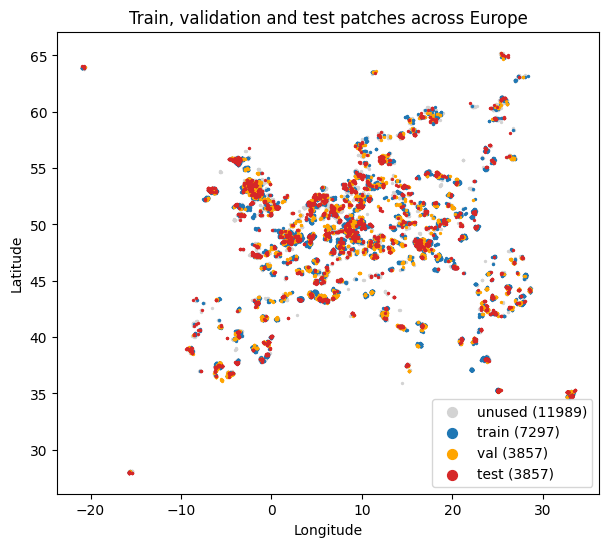

Largest number of splits any block appears in: 1


In [8]:
# Step 8: Load the split that the pipeline made, and plot where each split is on the map
splits = pd.read_csv(ROOT / "artifacts" / "splits.csv")
meta = meta.merge(splits[["idx", "split", "train_full"]], on="idx")

plt.figure(figsize=(7, 6))
for split, colour in [("unused", "lightgrey"), ("train", "tab:blue"), ("val", "orange"), ("test", "tab:red")]:
    part = meta[meta["split"] == split]
    plt.scatter(part["lon"], part["lat"], s=2, c=colour, label=f"{split} ({len(part)})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Train, validation and test patches across Europe")
plt.legend(markerscale=5)
plt.show()

# Check: no block is shared between two splits
used = meta[meta["split"] != "unused"]
print("Largest number of splits any block appears in:", used.groupby("block")["split"].nunique().max())

In [9]:
# Step 9: Did the spatial split work? Distance from each test patch to its nearest training patch
leak = pd.read_csv(ROOT / "reports" / "leakage_check.csv")
leak

,split,median_km_to_nearest_train,share_within_1km,share_adjacent_0.7km
0,spatial,4.216882,0.070780,0.045372
1,random,0.919511,0.514649,0.408348


**What does this tell us?** With a random split, **41%** of test patches would touch a training patch (centres less
than 0.7 km apart, and a patch is 0.64 km wide). With our block split only **4.5%** do, and only at block borders.
The median distance to the nearest training patch goes from 0.9 km to 4.2 km.

**Problem 2: real landscapes are imbalanced.** Cropland and forest dominate, while highways, industry and rivers are
rare.

**Fix: subsample the training set.** Class sizes fall step by step from AnnualCrop (kept in full) to Highway, so the
largest class is **20 times** the smallest. Validation and test are **not touched**, so the model is still judged
on every class fairly.

In [10]:
# Step 10: Class counts in each split
counts = pd.crosstab(meta["class_name"], meta["split"]).loc[CLASSES, ["train", "val", "test"]]
counts["train_full"] = meta[meta["train_full"]].groupby("class_name").size()
counts

split,train,val,test,train_full
class_name,,,,
AnnualCrop,2143,428,429,2143
Forest,1536,429,429,2142
HerbaceousVegetation,1101,428,429,2143
Pasture,789,286,285,1429
PermanentCrop,566,357,357,1786
SeaLake,406,428,429,2143
Residential,291,429,428,2143
River,209,357,357,1786
Industrial,149,358,357,1785


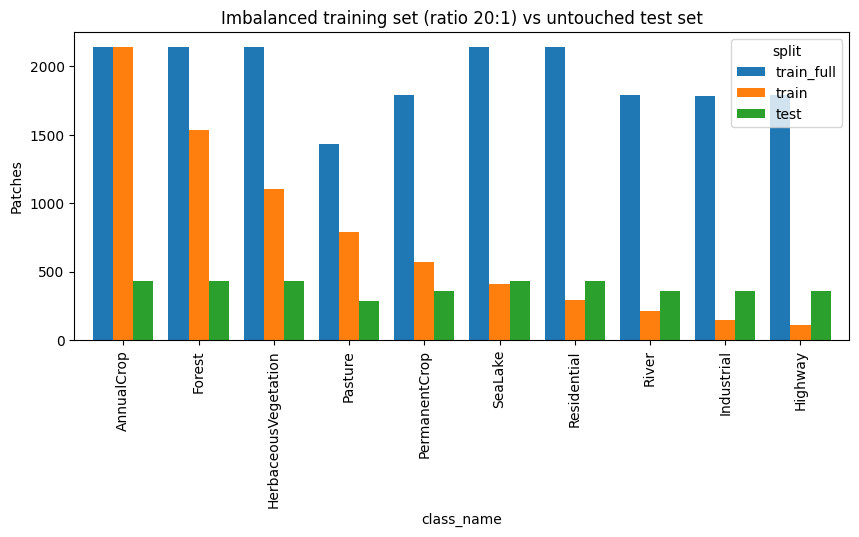

In [11]:
# Step 11: Plot it
counts[["train_full", "train", "test"]].plot.bar(figsize=(10, 4), width=0.8)
plt.ylabel("Patches")
plt.title(f"Imbalanced training set (ratio {counts['train'].max() / counts['train'].min():.0f}:1) vs untouched test set")
plt.show()

**What does this tell us?** The training set now has 2,143 AnnualCrop patches but only 107 Highway patches. The test
set still has 285–429 per class.

Because the test set is balanced, we use **macro F1** as the main score: it is the plain average of the F1 score of
each class, so every class counts equally. Accuracy would let a model look good while ignoring the rare classes, as
we saw in Lab 03. We also report **minority F1**, the average F1 of the four classes made rarest in training
(Residential, River, Industrial, Highway), and the **recall** of each class: of all the real highways in the test
area, what fraction did the model find?

`train_full` is the whole training pool before subsampling. It is used only once, in Step 28, as a balanced
reference.

## 3. Baseline: random forest on band statistics

Before any deep learning we need a baseline. Conventional remote sensing classifies a patch from summary numbers per
band rather than from the image itself. For each of the 13 bands we take the mean, standard deviation, 10th and 90th
percentile, and we add the same four statistics of **NDVI**, a vegetation index:

$$NDVI = \frac{NIR - Red}{NIR + Red}$$

That gives 56 numbers per patch. A random forest is then trained on these numbers (Lab 04).

In [12]:
# Step 12: The 56 features. Computing them for 27,000 patches takes a few minutes, so the pipeline saved them
features = np.load(ROOT / "artifacts" / "features.npy")
names = feature_names(BANDS)
print("Feature matrix:", features.shape)
print("First features:", names[:5], "...", names[-4:])

Feature matrix: (27000, 56)
First features: ['B01_mean', 'B02_mean', 'B03_mean', 'B04_mean', 'B05_mean'] ... ['NDVI_mean', 'NDVI_std', 'NDVI_p10', 'NDVI_p90']


In [13]:
# Step 13: Make train / validation / test sets from the split
y = meta["label"].to_numpy()
train = (meta["split"] == "train").to_numpy()
test = (meta["split"] == "test").to_numpy()

X_train, y_train = features[train], y[train]
X_test, y_test = features[test], y[test]
print("Train:", X_train.shape, "  Test:", X_test.shape)

Train: (7297, 56)   Test: (3857, 56)


In [14]:
# Step 14: Train the random forest. class_weight="balanced" gives rare classes more weight
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, max_features="sqrt",
                            class_weight="balanced", n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print(classification_report(y_test, rf_pred, target_names=CLASSES, digits=3))

                      precision    recall  f1-score   support

          AnnualCrop      0.662     0.909     0.766       429
              Forest      0.974     0.958     0.966       429
HerbaceousVegetation      0.812     0.956     0.878       429
             Pasture      0.801     0.919     0.856       285
       PermanentCrop      0.836     0.784     0.809       357
             SeaLake      0.970     0.981     0.976       429
         Residential      0.831     0.876     0.853       428
               River      0.937     0.874     0.904       357
          Industrial      0.935     0.888     0.911       357
             Highway      0.893     0.305     0.455       357

            accuracy                          0.852      3857
           macro avg      0.865     0.845     0.837      3857
        weighted avg      0.865     0.852     0.842      3857



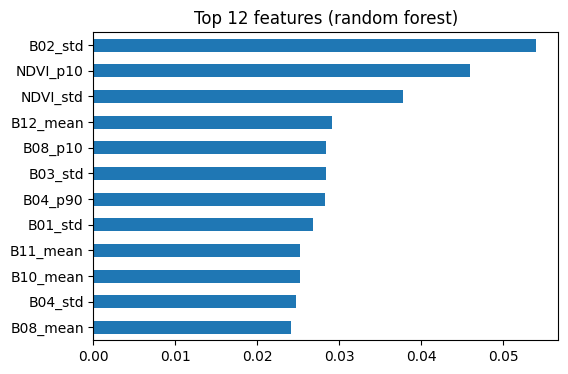

In [15]:
# Step 15: Which features does the forest rely on most?
importance = pd.Series(rf.feature_importances_, index=names).sort_values()
importance.tail(12).plot.barh(figsize=(6, 4), title="Top 12 features (random forest)")
plt.show()

**What does this tell us?** The baseline already reaches a **macro F1 of about 0.84**. Spectral statistics alone
separate water, forest and vegetation well. The near-infrared and short-wave infrared bands, and NDVI, are among the most
useful features. But **Highway recall is only about 0.31**: averaging a whole patch into 56 numbers throws away the
shape of a road, and with only 107 training examples the forest cannot recover it.

(Ignoring geography would barely help this baseline: the pipeline also trained it on a random split, with test macro
F1 0.835 against 0.837. Whole-patch statistics do not exploit near-duplicate neighbours much. CNNs, which learn local
texture, are the models expected to.)

## 4. Custom CNN

As in Lab 07, a CNN learns its own features from the pixels with small sliding filters. Our architecture:

**Normalise bands -> [Conv2D -> BatchNorm -> ReLU -> MaxPool] x 3 (32, 64, 128 filters) -> GlobalAveragePooling -> Dropout(0.5) -> Softmax(10)**

* The **Normalization** layer subtracts each band's mean and divides by its standard deviation, with the statistics
  learned from the **training set only**. It is saved inside the model, so the API can pass raw pixels.
* **GlobalAveragePooling** averages each feature map into one number, which needs far fewer weights than `Flatten`.
* **Augmentation:** random flips and 90-degree rotations. In Lab 07 we did *not* flip chest X-rays, because a body
  has a left and a right side. A satellite image seen from above has no "correct" way up, so all eight
  orientations are valid.

The model is trained twice on each input: RGB (3 bands) and all 13 bands.

In [16]:
# Step 16: Build the custom CNN (13-band version) and look at its layers
import keras
from pipeline.models import custom_cnn

sample = patches[:200].astype("float32")          # a small sample, only to initialise the Normalization layer here
model = custom_cnn(n_channels=13, normaliser_data=sample)
model.summary()

Model: "custom_cnn_13band"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ patch (InputLayer)              │ (None, 64, 64, 13)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ band_normalisation              │ (None, 64, 64, 13)     │            27 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         3,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,117 (383.27 KB)

 Trainable params: 97,642 (381.41 KB)

 Non-trainable params: 475 (1.86 KB)

The model has only about 100,000 trainable weights. A Dense layer on the flattened 64 x 64 x 13 image would need over
six million weights for 128 units, which is why CNNs are used for images.

Each version was trained with three loss functions (see `pipeline/train.py`):
* **ce:** normal cross-entropy, with no imbalance handling.
* **weighted_ce:** cross-entropy with class weights, `weight = n_samples / (n_classes x n_class)`. A Highway mistake
  costs about 6.8 times an average mistake, and an AnnualCrop mistake about a third of one.
* **focal:** focal loss, which gives less weight to examples the model already gets right (used for EfficientNet).

Training used the Adam optimiser and **early stopping on validation macro F1**, which keeps the epoch that scores best
on the validation set. Training commands, for example:

```bash
python -m pipeline.train --model cnn --bands ms --loss weighted_ce
```

In [17]:
# Step 17: Load the test set (all 13 bands) and an RGB copy of it
test_idx = meta.loc[test, "idx"].to_numpy()
X_test_ms = np.asarray(patches[test_idx])        # (3857, 64, 64, 13)
X_test_rgb = to_rgb8(X_test_ms)                  # (3857, 64, 64, 3)
print("13-band test set:", X_test_ms.shape, "  RGB test set:", X_test_rgb.shape)

13-band test set: (3857, 64, 64, 13)   RGB test set: (3857, 64, 64, 3)


In [18]:
# Step 18: A helper that loads a trained model and predicts the test set
MODEL_DIR = ROOT / "artifacts" / "models"

def predict_test(run_name):
    model = keras.models.load_model(MODEL_DIR / f"{run_name}.keras")
    X = X_test_ms if model.input_shape[-1] == 13 else X_test_rgb
    return model.predict(X.astype("float32"), batch_size=256, verbose=0)    # probabilities, one column per class

proba = predict_test("cnn_rgb_ce")
pred = proba.argmax(axis=1)                      # the class with the highest probability
print("Custom CNN, RGB, no imbalance handling\n")
print(classification_report(y_test, pred, target_names=CLASSES, digits=3))

Custom CNN, RGB, no imbalance handling

                      precision    recall  f1-score   support

          AnnualCrop      0.717     0.963     0.822       429
              Forest      0.898     0.986     0.940       429
HerbaceousVegetation      0.705     0.858     0.774       429
             Pasture      0.646     0.933     0.763       285
       PermanentCrop      0.739     0.818     0.777       357
             SeaLake      0.997     0.716     0.833       429
         Residential      0.900     0.967     0.932       428
               River      0.707     0.594     0.645       357
          Industrial      0.892     0.899     0.895       357
             Highway      0.962     0.143     0.249       357

            accuracy                          0.795      3857
           macro avg      0.816     0.788     0.763      3857
        weighted avg      0.822     0.795     0.772      3857



**What does this tell us?** The RGB CNN trained without any imbalance handling reaches about 80% accuracy, which sounds
fine. But look at the **recall** column: it finds 96% of AnnualCrop patches and only **14% of Highway** patches. The
rarer a class was in training, the worse it does, and **accuracy hides this**. This is exactly the problem in the
research question.

In [19]:
# Step 19: Same CNN with class weights, and the 13-band versions
for run in ["cnn_rgb_weighted_ce", "cnn_ms_ce", "cnn_ms_weighted_ce"]:
    pred = predict_test(run).argmax(axis=1)
    recall = recall_score(y_test, pred, average=None)
    print(f"{run:22}  macro F1 = {f1_score(y_test, pred, average='macro'):.3f}   "
          f"Highway recall = {recall[CLASSES.index('Highway')]:.3f}   River recall = {recall[CLASSES.index('River')]:.3f}")

cnn_rgb_weighted_ce     macro F1 = 0.821   Highway recall = 0.692   River recall = 0.720


cnn_ms_ce               macro F1 = 0.883   Highway recall = 0.353   River recall = 0.899


cnn_ms_weighted_ce      macro F1 = 0.926   Highway recall = 0.737   River recall = 0.941


C:\Users\kipro\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


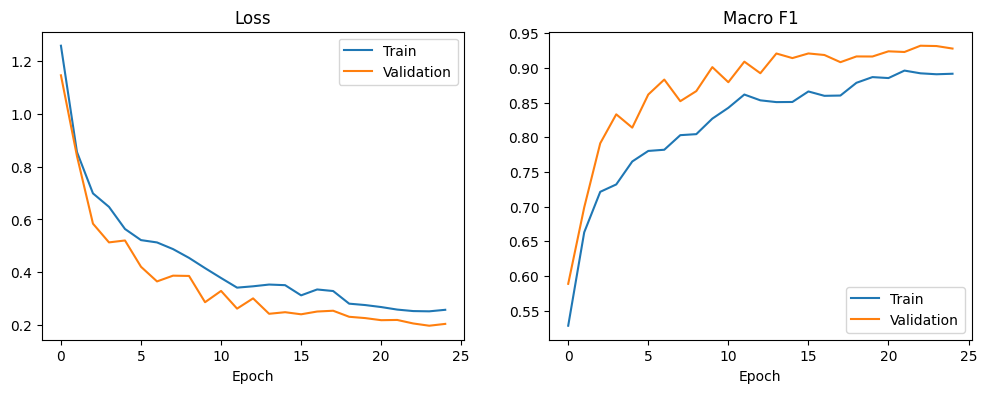

In [20]:
# Step 20: Training curves of the 13-band weighted CNN (read back from MLflow, where training logged every epoch)
import mlflow
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
client = mlflow.MlflowClient()
runs = mlflow.search_runs(experiment_names=["capstone_eurosat_lulc"], filter_string="attributes.status = 'FINISHED'")
run_id = {name: rid for name, rid in zip(runs["tags.mlflow.runName"], runs["run_id"])}

def history(run, key):
    return [m.value for m in sorted(client.get_metric_history(run_id[run], key), key=lambda m: m.step)]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history("cnn_ms_weighted_ce", "epoch_loss"), label="Train")
plt.plot(history("cnn_ms_weighted_ce", "epoch_val_loss"), label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history("cnn_ms_weighted_ce", "epoch_macro_f1"), label="Train")
plt.plot(history("cnn_ms_weighted_ce", "epoch_val_macro_f1"), label="Validation")
plt.title("Macro F1")
plt.xlabel("Epoch")
plt.legend()
plt.show()

**What does this tell us?**
* **Class weights help a lot.** For the RGB CNN, Highway recall rises from 0.14 to about 0.69 and macro F1 from 0.76
  to 0.82.
* **All 13 bands help even more.** The 13-band CNN beats the RGB one with or without weights, and with weights it
  reaches a macro F1 of about **0.93**, with Highway recall 0.74 and River recall 0.94.
* In the curves, validation macro F1 rises and then levels off while training keeps improving: the start of
  overfitting. Early stopping keeps the best validation epoch.

## 5. Transfer learning: EfficientNet-B0

As with MobileNetV2 in Lab 07, we reuse a network pretrained on ImageNet's 1.2 million photos. EfficientNet-B0 is
small and fast. Training has two stages:
1. **Frozen:** keep the pretrained weights fixed and train only a new classification head (Dropout -> Softmax(10)).
2. **Fine-tune:** unfreeze the top 40 layers and train them slowly (learning rate 1e-4) with augmentation, keeping
   BatchNorm layers frozen.

ImageNet weights only exist for 3 colour channels, so EfficientNet uses **RGB only**.

In [21]:
# Step 21: Build EfficientNet-B0 and see how big it is
from pipeline.models import efficientnet_b0

effnet, base, extractor, head = efficientnet_b0(img_size=64)
print("Layers in the pretrained base:", len(base.layers))
print("Total parameters:", f"{effnet.count_params():,}")
print("Trainable in stage 1 (head only):", f"{sum(np.prod(w.shape) for w in effnet.trainable_weights):,}")

Layers in the pretrained base: 238
Total parameters: 4,062,381
Trainable in stage 1 (head only): 12,810


In [22]:
# Step 22: Evaluate the three EfficientNet models (plain, class-weighted, focal loss)
for run in ["effnet_rgb_ce", "effnet_rgb_weighted_ce", "effnet_rgb_focal"]:
    pred = predict_test(run).argmax(axis=1)
    recall = recall_score(y_test, pred, average=None)
    print(f"{run:24}  macro F1 = {f1_score(y_test, pred, average='macro'):.3f}   "
          f"Highway recall = {recall[CLASSES.index('Highway')]:.3f}")

effnet_rgb_ce             macro F1 = 0.903   Highway recall = 0.700


effnet_rgb_weighted_ce    macro F1 = 0.923   Highway recall = 0.807


effnet_rgb_focal          macro F1 = 0.910   Highway recall = 0.734


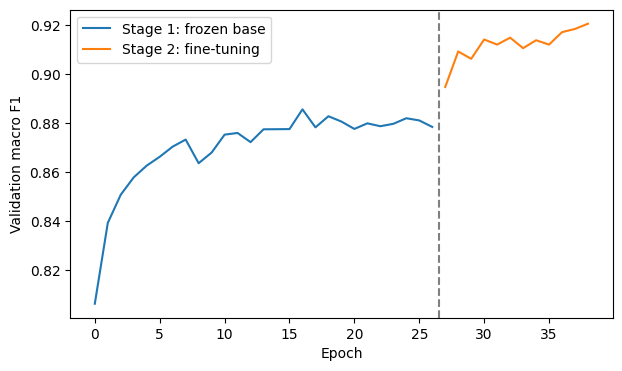

In [23]:
# Step 23: Training curve of the weighted EfficientNet: frozen stage, then fine-tuning
frozen = history("effnet_rgb_weighted_ce", "frozen_val_macro_f1")
finetune = history("effnet_rgb_weighted_ce", "finetune_val_macro_f1")

plt.figure(figsize=(7, 4))
plt.plot(range(len(frozen)), frozen, label="Stage 1: frozen base")
plt.plot(range(len(frozen), len(frozen) + len(finetune)), finetune, label="Stage 2: fine-tuning")
plt.axvline(len(frozen) - 0.5, ls="--", c="grey")
plt.xlabel("Epoch")
plt.ylabel("Validation macro F1")
plt.legend()
plt.show()

**What does this tell us?**
* **Transfer learning is the biggest single improvement on RGB.** Without any imbalance handling, EfficientNet reaches
  macro F1 about 0.90 and finds **70% of highways**, against 14% for our own RGB CNN. Filters pretrained on edges,
  lines and textures already describe roads and rivers, so far fewer examples are needed.
* **Class weights still help**: macro F1 rises to about 0.92 and Highway recall to **0.81**, the best of any model
  trained on the imbalanced data.
* **Focal loss** helped less than class weights. It focuses on *hard* examples, while class weights target *rare*
  ones directly.
* In the curve, fine-tuning lifts validation macro F1 from about 0.89 (frozen) to 0.92.

## 6. Compare all models: answer the research question

In [24]:
# Step 24: Predict the test set with every model and collect the scores in one table
MINORITY = ["Residential", "River", "Industrial", "Highway"]          # the 4 classes made rarest in training
minority_ids = [CLASSES.index(c) for c in MINORITY]

predictions = {"rf_balanced": rf_pred}
for run in ["cnn_rgb_ce", "cnn_rgb_weighted_ce", "cnn_ms_ce", "cnn_ms_weighted_ce",
            "effnet_rgb_ce", "effnet_rgb_weighted_ce", "effnet_rgb_focal", "cnn_ms_ce_fulltrain"]:
    predictions[run] = predict_test(run).argmax(axis=1)

rows = []
for run, pred in predictions.items():
    f1_per_class = f1_score(y_test, pred, average=None)
    recall = recall_score(y_test, pred, average=None)
    rows.append({"model": run,
                 "accuracy": (pred == y_test).mean(),
                 "macro F1": f1_score(y_test, pred, average="macro"),
                 "minority F1": f1_per_class[minority_ids].mean(),
                 "Highway recall": recall[CLASSES.index("Highway")]})
results = pd.DataFrame(rows).set_index("model").round(3)
results.sort_values("macro F1", ascending=False)

,accuracy,macro F1,minority F1,Highway recall
model,,,,
cnn_ms_ce_fulltrain,0.971,0.970,0.964,0.927
cnn_ms_weighted_ce,0.929,0.926,0.906,0.737
effnet_rgb_weighted_ce,0.927,0.923,0.917,0.807
effnet_rgb_focal,0.914,0.910,0.899,0.734
effnet_rgb_ce,0.908,0.903,0.892,0.700
cnn_ms_ce,0.898,0.883,0.816,0.353
rf_balanced,0.852,0.837,0.781,0.305
cnn_rgb_weighted_ce,0.826,0.821,0.818,0.692
cnn_rgb_ce,0.795,0.763,0.680,0.143


`cnn_ms_ce_fulltrain` is the **balanced reference**: the 13-band CNN trained on the full, roughly balanced training
pool. It shows how well the model would do with no imbalance.

In [25]:
# Step 25: Recall of every class for every model (rows = classes, from most to least common in training)
recall_table = pd.DataFrame({run: recall_score(y_test, pred, average=None) for run, pred in predictions.items()},
                            index=CLASSES).round(2)
recall_table.insert(0, "n_train", counts["train"])
recall_table

,n_train,rf_balanced,cnn_rgb_ce,cnn_rgb_weighted_ce,cnn_ms_ce,cnn_ms_weighted_ce,effnet_rgb_ce,effnet_rgb_weighted_ce,effnet_rgb_focal,cnn_ms_ce_fulltrain
AnnualCrop,2143,0.91,0.96,0.86,0.99,0.95,0.97,0.94,0.97,0.98
Forest,1536,0.96,0.99,0.94,1.00,0.98,0.98,0.97,0.99,1.00
HerbaceousVegetation,1101,0.96,0.86,0.68,0.94,0.91,0.93,0.92,0.93,0.97
Pasture,789,0.92,0.93,0.90,0.94,0.93,0.88,0.91,0.92,0.96
PermanentCrop,566,0.78,0.82,0.84,0.92,0.90,0.80,0.84,0.83,0.96
SeaLake,406,0.98,0.72,0.75,0.99,0.99,0.96,0.97,0.95,0.98
Residential,291,0.88,0.97,0.97,0.97,0.95,0.97,0.98,0.98,0.99
River,209,0.87,0.59,0.72,0.90,0.94,0.89,0.91,0.87,0.96
Industrial,149,0.89,0.90,0.91,0.91,0.97,0.93,0.97,0.92,0.97
Highway,107,0.31,0.14,0.69,0.35,0.74,0.70,0.81,0.73,0.93


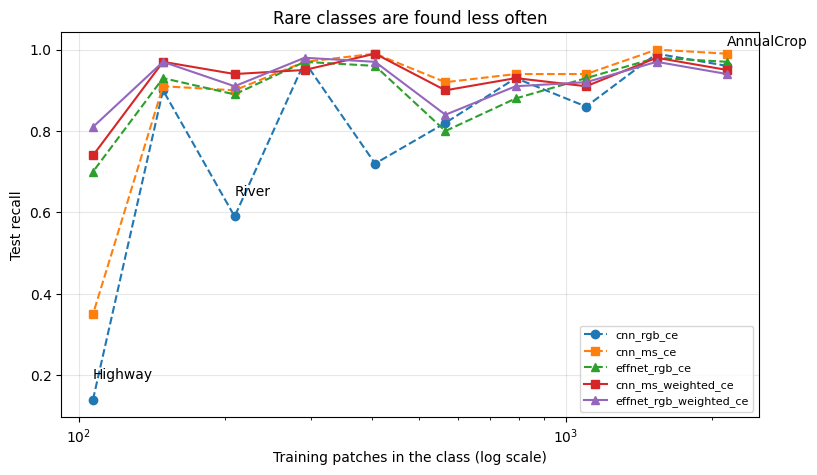

In [26]:
# Step 26: Plot recall against how many training patches the class had
plt.figure(figsize=(9, 5))
for run, style in [("cnn_rgb_ce", "o--"), ("cnn_ms_ce", "s--"), ("effnet_rgb_ce", "^--"),
                   ("cnn_ms_weighted_ce", "s-"), ("effnet_rgb_weighted_ce", "^-")]:
    plt.plot(counts["train"], recall_table[run], style, label=run)
plt.xscale("log")
plt.xlabel("Training patches in the class (log scale)")
plt.ylabel("Test recall")
plt.title("Rare classes are found less often")
for c in ["Highway", "River", "AnnualCrop"]:
    plt.annotate(c, (counts.loc[c, "train"], 0.05 + recall_table.loc[c, "cnn_rgb_ce"]))
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

**What does this tell us?** Almost every model finds 95–100% of the common classes. The damage is concentrated in the
rarest class, **Highway** (107 training patches), and for the RGB CNN also **River** (209). The dashed lines (no
imbalance handling) drop sharply on the left; the solid lines (with class weights) stay much higher.

In [27]:
# Step 27: The effect of class weights, model by model
pairs = [("CNN RGB", "cnn_rgb_ce", "cnn_rgb_weighted_ce"),
         ("CNN 13-band", "cnn_ms_ce", "cnn_ms_weighted_ce"),
         ("EfficientNet RGB", "effnet_rgb_ce", "effnet_rgb_weighted_ce")]
effect = pd.DataFrame({name: {"macro F1 without weights": results.loc[a, "macro F1"],
                              "macro F1 with weights": results.loc[b, "macro F1"],
                              "Highway recall without": results.loc[a, "Highway recall"],
                              "Highway recall with": results.loc[b, "Highway recall"]}
                       for name, a, b in pairs}).T

# Class weights also have a cost: the model now predicts rare classes more often, including wrongly
h = CLASSES.index("Highway")
before = precision_score(y_test, predictions["cnn_rgb_ce"], average=None)[h]
after = precision_score(y_test, predictions["cnn_rgb_weighted_ce"], average=None)[h]
print(f"Highway precision of the RGB CNN: {before:.2f} without weights -> {after:.2f} with weights")
effect

Highway precision of the RGB CNN: 0.96 without weights -> 0.70 with weights


,macro F1 without weights,macro F1 with weights,Highway recall without,Highway recall with
CNN RGB,0.763,0.821,0.143,0.692
CNN 13-band,0.883,0.926,0.353,0.737
EfficientNet RGB,0.903,0.923,0.700,0.807


**What does this tell us?** Class weights improved **every** model, most of all for the rare classes. They are not
free, though: the weighted model predicts Highway more often, so its Highway *precision* falls (from 0.96 to 0.70
for the RGB CNN), and a few common-class patches are now mislabelled. On a balanced test set the gain is bigger than
the loss. Whether that trade-off is right in real life depends on what a missed highway costs compared with a false
alarm, the same cost-matrix question as in Lab 03.

In [28]:
# Step 28: How much of the gap to balanced training is closed?
gap = results.loc[["cnn_ms_ce", "cnn_ms_weighted_ce", "effnet_rgb_weighted_ce", "cnn_ms_ce_fulltrain"],
                  ["macro F1", "minority F1", "Highway recall"]]
full_gap = gap.loc["cnn_ms_ce_fulltrain"] - gap.loc["cnn_ms_ce"]
closed = (gap.loc["cnn_ms_weighted_ce"] - gap.loc["cnn_ms_ce"]) / full_gap
print("Share of the gap closed by class weights (13-band CNN):")
print(closed.round(2))
gap

Share of the gap closed by class weights (13-band CNN):
macro F1          0.49
minority F1       0.61
Highway recall    0.67
dtype: float64


,macro F1,minority F1,Highway recall
model,,,
cnn_ms_ce,0.883,0.816,0.353
cnn_ms_weighted_ce,0.926,0.906,0.737
effnet_rgb_weighted_ce,0.923,0.917,0.807
cnn_ms_ce_fulltrain,0.970,0.964,0.927


**What does this tell us?** Imbalance costs the 13-band CNN about 0.09 macro F1 and 0.15 minority F1 compared with
balanced training. Class weights recover about **half** of the macro-F1 gap and about **60%** of the minority gap, but
not all of it: Highway recall is 0.74 with weights against 0.93 with balanced data. Part of the remaining gap is simply
less data: the imbalanced set is 2.6 times smaller (7,297 against 19,286 patches), and no loss function can replace
missing examples.

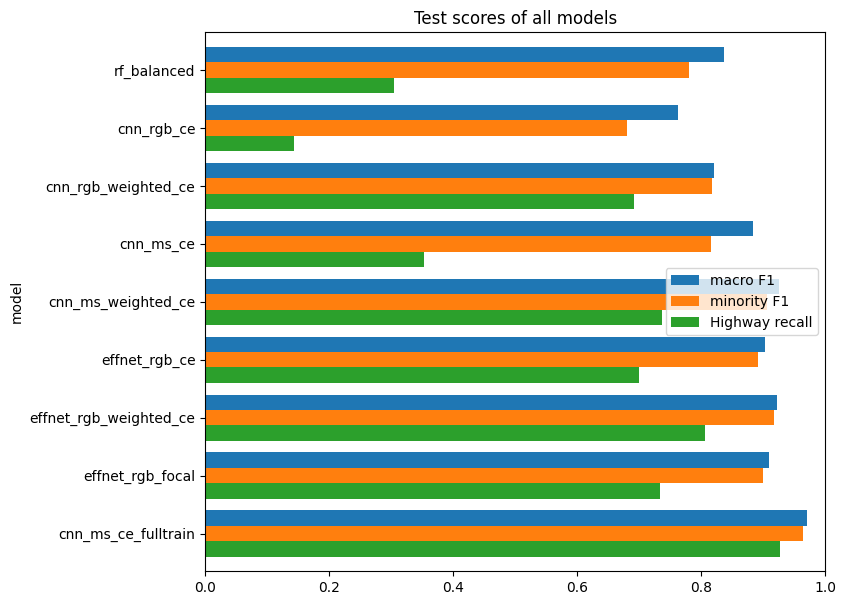

In [29]:
# Step 29: The final comparison in one chart
show = ["rf_balanced", "cnn_rgb_ce", "cnn_rgb_weighted_ce", "cnn_ms_ce", "cnn_ms_weighted_ce",
        "effnet_rgb_ce", "effnet_rgb_weighted_ce", "effnet_rgb_focal", "cnn_ms_ce_fulltrain"]
results.loc[show, ["macro F1", "minority F1", "Highway recall"]].plot.barh(figsize=(8, 7), width=0.8)
plt.gca().invert_yaxis()
plt.xlim(0, 1)
plt.title("Test scores of all models")
plt.show()

### Answer to the research question

* **How well does a CNN recognise minority classes under imbalance?** Poorly, if it is trained naively. With a 20:1
  imbalance the RGB CNN finds only 14% of highways and the 13-band CNN 35%, while common classes are found 95–100% of
  the time. Overall accuracy (80–90%) hides this completely.
* **Does transfer learning with imbalance-aware training close the gap?** It closes **most** of it, not all.
  EfficientNet-B0 with class weights has the best minority F1 (0.92) and Highway recall (0.81) of all models trained
  on imbalanced data, against 0.93 for balanced training.
* **Class weights were the most reliable fix**, improving every model. Transfer learning was the largest single gain
  on RGB, and the **13 spectral bands** were worth about as much as ImageNet pretraining.

## 7. The champion model

`pipeline/select_champion.py` chooses the model to deploy using a rule fixed **before** looking at test results: the
best **validation** macro F1 among models trained on the imbalanced data. It applies a quality gate (validation macro
F1 of at least 0.80, otherwise nothing is deployed, as in `fraud_mlops`), registers the model in MLflow as `champion`,
and copies it to `model/` for the API.

In [30]:
# Step 30: Which model was chosen, and why?
metadata = json.loads((ROOT / "model" / "metadata.json").read_text())
print("Champion:", metadata["run"])
print("Validation macro F1:", metadata["metrics"]["val_macro_f1"], " (used to choose)")
print("Test macro F1:      ", metadata["metrics"]["test_macro_f1"], " (only reported)")

Champion: cnn_ms_weighted_ce
Validation macro F1: 0.932  (used to choose)
Test macro F1:       0.9261  (only reported)


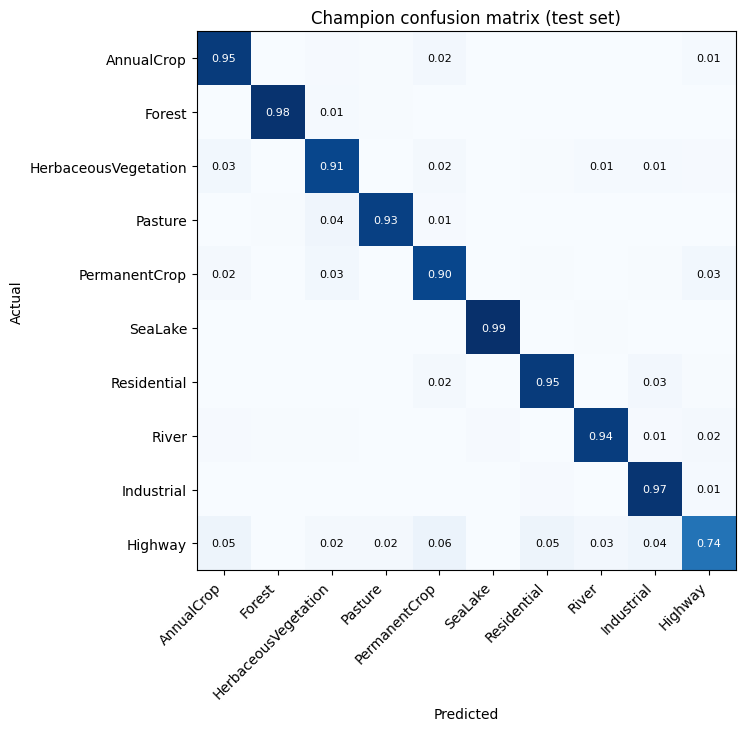

Highway test patches were predicted as:
 Highway                 263
PermanentCrop            21
Residential              18
AnnualCrop               17
Industrial               16
River                     9
Pasture                   7
HerbaceousVegetation      6
Name: count, dtype: int64


In [31]:
# Step 31: Confusion matrix of the champion: where does it get confused?
champ_pred = predictions[metadata["run"]]
cm = confusion_matrix(y_test, champ_pred, normalize="true")       # each row sums to 1, so the diagonal is recall

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), CLASSES, rotation=45, ha="right")
plt.yticks(range(10), CLASSES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Champion confusion matrix (test set)")
for i in range(10):
    for j in range(10):
        if cm[i, j] >= 0.01:
            plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if cm[i, j] > 0.5 else "black")
plt.show()

missed = pd.Series(champ_pred[y_test == CLASSES.index("Highway")]).map(dict(enumerate(CLASSES))).value_counts()
print("Highway test patches were predicted as:\n", missed)

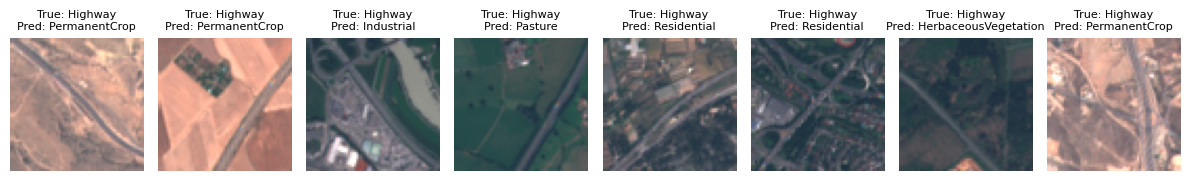

In [32]:
# Step 32: Look at some highways the champion missed
wrong = np.where((y_test == CLASSES.index("Highway")) & (champ_pred != y_test))[0][:8]
plt.figure(figsize=(12, 3.5))
for k, i in enumerate(wrong):
    plt.subplot(1, 8, k + 1)
    plt.imshow(X_test_rgb[i])
    plt.title(f"True: Highway\nPred: {CLASSES[champ_pred[i]]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

**What does this tell us?** The champion is the **13-band CNN with class weights** (validation macro F1 0.932, test
0.926). Its test score is close to its validation score, so choosing on validation did not overfit. Every class has
recall of at least 0.90 except Highway (0.74). The missed highways are split between the land a road crosses
(AnnualCrop, PermanentCrop) and the built-up areas it serves (Residential, Industrial). The pictures show why: in many
patches the road is a thin line and most of the patch is something else. At 640 m a patch is labelled by its main use,
but the land is mixed.

## 8. Deployment: the FastAPI service

The champion is served by `api/main.py` (as in Lab 10). `POST /predict` takes a 64 x 64 patch as a 13-band GeoTIFF
file and returns the predicted class, its probability and the **top three** classes. FastAPI's `TestClient` lets us
call the API here without starting a server.

In [33]:
# Step 33: Call the API on the 10 sample patches (one per class, taken from the test set)
from fastapi.testclient import TestClient
from api.main import app

client_api = TestClient(app)
print(client_api.get("/health").json())

rows = []
for path in sorted((ROOT / "samples").glob("*.tif")):
    answer = client_api.post("/predict", files={"file": (path.name, path.read_bytes())}).json()
    rows.append({"true class": path.stem, "predicted": answer["predicted_class"],
                 "confidence": answer["confidence"], "second choice": answer["top3"][1]["class"]})
api_results = pd.DataFrame(rows)
print(f"{(api_results['true class'] == api_results['predicted']).sum()} / 10 correct")
api_results

{'status': 'ok'}


7 / 10 correct


,true class,predicted,confidence,second choice
0,AnnualCrop,AnnualCrop,0.9724,PermanentCrop
1,Forest,Forest,0.9893,Highway
2,HerbaceousVegetation,River,0.4305,HerbaceousVegetation
3,Highway,PermanentCrop,0.8212,HerbaceousVegetation
4,Industrial,Industrial,0.9997,Highway
5,Pasture,Pasture,0.9891,Forest
6,PermanentCrop,PermanentCrop,0.9775,Residential
7,Residential,Residential,0.9855,Highway
8,River,SeaLake,0.8078,River
9,SeaLake,SeaLake,0.9993,River


In [34]:
# Step 34: The full JSON answer for one patch
answer = client_api.post("/predict", files={"file": ("Industrial.tif", (ROOT / "samples" / "Industrial.tif").read_bytes())})
print(json.dumps(answer.json(), indent=2))

{
  "predicted_class": "Industrial",
  "confidence": 0.9997,
  "top3": [
    {
      "class": "Industrial",
      "probability": 0.9997
    },
    {
      "class": "Highway",
      "probability": 0.0002
    },
    {
      "class": "Residential",
      "probability": 0.0
    }
  ],
  "model_version": 1
}


**What does this tell us?** The API gets 7 of the 10 samples right. Two of the three mistakes (River called SeaLake,
HerbaceousVegetation called River) have the right class as the **second choice**, which is why the API returns the top
three: the test-set top-3 accuracy is 0.99.

To run the service yourself:
```bash
uvicorn api.main:app --reload       # API with interactive docs at http://127.0.0.1:8000/docs
docker compose up --build            # web app and API at http://127.0.0.1:8000/
```

## 9. Summary

### What should you remember?
1. **Accuracy hides the problem.** Trained on imbalanced data, a CNN can score 80–90% accuracy and still miss most
   highways. Use **macro F1** and **per-class recall**.
2. **Split by location.** Neighbouring satellite patches are near-copies; a random split leaks them into the test set.
3. **Class weights** are a simple and reliable fix for imbalance. They trade some precision for much better recall
   on rare classes.
4. **Transfer learning** gives the largest gain when only RGB is available, because ImageNet filters already
   describe edges and textures.
5. **Use all the bands.** The infrared bands made a small 13-band CNN as good as a large pretrained RGB network.
6. Imbalance-aware training **narrows but does not close** the gap to balanced training (macro F1 0.926 against 0.970).

### Limitations
* **Each model was trained once** (seed 42). Differences of about 0.01 (for example 0.926 against 0.923) are within
  normal run-to-run variation, so they should not be over-interpreted. Repeating each run with several seeds and
  reporting mean ± standard deviation (as in Lab 03) was not possible on a CPU-only laptop.
* **Compute limits:** EfficientNet ran at the native 64 x 64 instead of an upsampled size, and the custom CNN was
  stopped at 25 epochs; the RGB CNN without weights was still improving and is probably under-trained.
* The effect of the spatial split was measured for the random forest only, not for the CNNs.
* ImageNet weights are RGB-only, so transfer learning could not use the infrared bands. A pretrained multispectral
  network would be the natural next step.
* EuroSAT patches are hand-picked and single-label. Real maps contain many mixed patches, which is where this model
  is weakest.

### AI-use declaration
As required by the course outline: **Claude Code (Anthropic, model Claude Opus 5.5)** was used as a coding assistant.
It wrote the pipeline scripts, the FastAPI service, the Streamlit UI, the tests, the Docker and CI configuration and
this notebook, following the design in my capstone proposal and the patterns from the course labs (Lab 03, Lab 07,
Lab 10, `fraud_mlops`). I reviewed the code and the results.

*[Patrick: edit this declaration so it accurately describes how you used the tool before submitting.]*

### Reference
Helber, P., Bischke, B., Dengel, A., & Borth, D. (2019). EuroSAT: A novel dataset and deep learning benchmark for land
use and land cover classification. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*,
12(7), 2217–2226.